# İş Odaklı Değerlendirme ve Model Yorumlanabilirliği

In [38]:
import json
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

In [39]:
DATA_PATH = "../data/telco_customer_churn.csv"

df = pd.read_csv(DATA_PATH)

In [40]:
new_customer_missing = (
    df["TotalCharges"].str.strip().eq("")
    & df["tenure"].eq(0)
)

df.loc[
    new_customer_missing,
    "TotalCharges"
] = "0"

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [41]:
X = df.drop(
    columns=["customerID", "Churn"]
)

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [43]:
tuned_models = {
    "Logistic Regression": joblib.load(
        "../models/logistic_regression_tuned.joblib"
    ),
    "XGBoost": joblib.load(
        "../models/xgboost_tuned.joblib"
    )
}

In [44]:
cv = StratifiedKFold(
 n_splits=5,
 shuffle=True,
 random_state=42
)

In [45]:
def analyze_thresholds(
    y_true,
    probabilities,
    campaign_cost=50,
    lost_customer_cost=500
):
    thresholds = np.round(
        np.arange(0.01, 1.00, 0.01),
        2
    )

    rows = []

    for threshold in thresholds:
        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            predictions
        ).ravel()

        targeted_customers = tp + fp

        total_cost = (
            targeted_customers * campaign_cost
            + fn * lost_customer_cost
        )

        rows.append({
            "Threshold": threshold,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Kampanya Gönderilen": targeted_customers,
            "Kampanya Maliyeti": (
                targeted_customers
                * campaign_cost
            ),
            "Kaçırılan Churn Zararı": (
                fn * lost_customer_cost
            ),
            "Toplam Maliyet": total_cost,
            "Precision": precision_score(
                y_true,
                predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_true,
                predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_true,
                predictions,
                zero_division=0
            ),
            "Accuracy": accuracy_score(
                y_true,
                predictions
            )
        })

    return pd.DataFrame(rows)

In [46]:
oof_probabilities = {}
threshold_tables = {}
business_rows = []

In [47]:
for model_name, model_pipeline in tuned_models.items():
    print(
        f"İşleniyor: {model_name}"
    )

    probabilities = cross_val_predict(
        estimator=model_pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_probabilities[model_name] = (
        probabilities
    )

    threshold_table = analyze_thresholds(
        y_true=y_train,
        probabilities=probabilities,
        campaign_cost=50,
        lost_customer_cost=500
    )

    threshold_tables[model_name] = (
        threshold_table
    )

    optimal_row = threshold_table.loc[
        threshold_table[
            "Toplam Maliyet"
        ].idxmin()
    ]

    default_row = threshold_table.loc[
        threshold_table[
            "Threshold"
        ].eq(0.50)
    ].iloc[0]

    business_rows.append({
        "Model": model_name,
        "Optimal Threshold": (
            optimal_row["Threshold"]
        ),
        "Optimal Maliyet": (
            optimal_row["Toplam Maliyet"]
        ),
        "Optimal Recall": (
            optimal_row["Recall"]
        ),
        "Optimal Precision": (
            optimal_row["Precision"]
        ),
        "Optimal F1": (
            optimal_row["F1"]
        ),
        "0.50 Maliyeti": (
            default_row["Toplam Maliyet"]
        ),
        "0.50 Recall": (
            default_row["Recall"]
        ),
        "0.50 Precision": (
            default_row["Precision"]
        ),
        "Tasarruf": (
            default_row["Toplam Maliyet"]
            - optimal_row["Toplam Maliyet"]
        ),
        "ROC-AUC": roc_auc_score(
            y_train,
            probabilities
        ),
        "PR-AUC": average_precision_score(
            y_train,
            probabilities
        )
    })  

İşleniyor: Logistic Regression
İşleniyor: XGBoost


In [48]:
business_comparison = pd.DataFrame(
    business_rows
)

In [49]:
business_comparison = (
    business_comparison
    .sort_values(
        by="Optimal Maliyet",
        ascending=True
    )
    .reset_index(drop=True)
)

business_comparison.round(4)

,Model,Optimal Threshold,Optimal Maliyet,Optimal Recall,Optimal Precision,Optimal F1,0.50 Maliyeti,0.50 Recall,0.50 Precision,Tasarruf,ROC-AUC,PR-AUC
0,XGBoost,0.07,215650.0,0.9706,0.3746,0.5406,415650.0,0.5217,0.6707,200000.0,0.8493,0.6665
1,Logistic Regression,0.13,216450.0,0.9291,0.4249,0.5831,399650.0,0.5492,0.6552,183200.0,0.8459,0.6580


In [50]:
business_comparison.to_csv(
    "../reports/business_threshold_comparison.csv",
    index=False
)

In [51]:
for model_name, table in threshold_tables.items():
    safe_name = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    table.to_csv(
        f"../reports/{safe_name}_threshold_analysis.csv",
        index=False
    )

In [52]:
selected_model_name = (
    business_comparison
    .iloc[0]["Model"]
)

selected_threshold = float(
    business_comparison
    .iloc[0]["Optimal Threshold"]
)

selected_model_name, selected_threshold

('XGBoost', 0.07)

In [53]:
selected_threshold_table = (
    threshold_tables[selected_model_name]
)

In [54]:
threshold_comparison = (
    selected_threshold_table[
        selected_threshold_table[
            "Threshold"
        ].isin([
            0.50,
            selected_threshold
        ])
    ]
)

threshold_comparison.round(4)

,Threshold,TN,FP,FN,TP,Kampanya Gönderilen,Kampanya Maliyeti,Kaçırılan Churn Zararı,Toplam Maliyet,Precision,Recall,F1,Accuracy
6,0.07,1717,2422,44,1451,3873,193650,22000,215650,0.3746,0.9706,0.5406,0.5623
49,0.50,3756,383,715,780,1163,58150,357500,415650,0.6707,0.5217,0.5869,0.8051


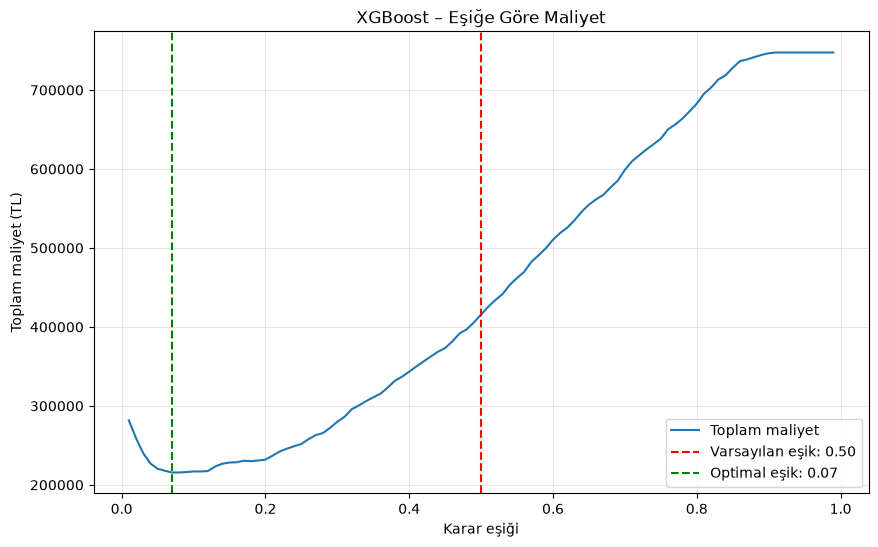

In [55]:
plt.figure(figsize=(10, 6))

plt.plot(
    selected_threshold_table[
        "Threshold"
    ],
    selected_threshold_table[
        "Toplam Maliyet"
    ],
    label="Toplam maliyet"
)

plt.axvline(
    x=0.50,
    color="red",
    linestyle="--",
    label="Varsayılan eşik: 0.50"
)

plt.axvline(
    x=selected_threshold,
    color="green",
    linestyle="--",
    label=(
        f"Optimal eşik: "
        f"{selected_threshold:.2f}"
    )
)

plt.title(
    f"{selected_model_name} – Eşiğe Göre Maliyet"
)
plt.xlabel("Karar eşiği")
plt.ylabel("Toplam maliyet (TL)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

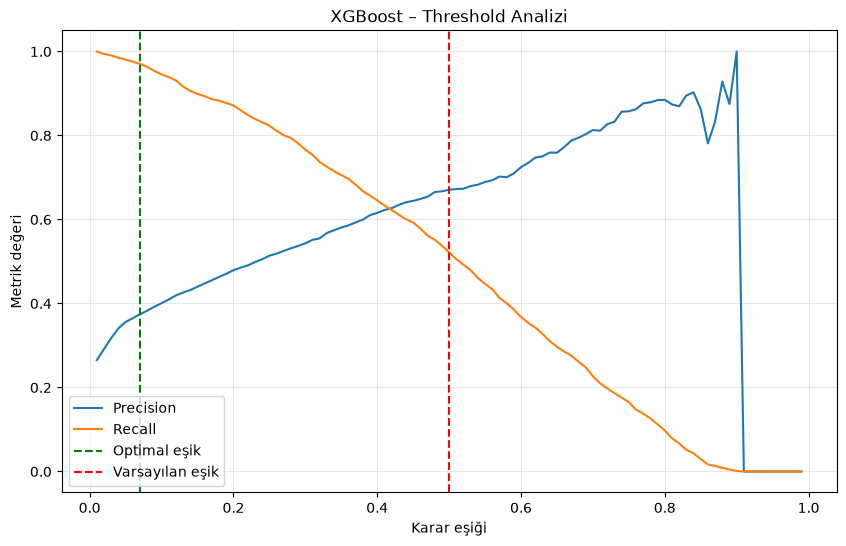

In [56]:
plt.figure(figsize=(10, 6))

plt.plot(
    selected_threshold_table[
        "Threshold"
    ],
    selected_threshold_table[
        "Precision"
    ],
    label="Precision"
)

plt.plot(
    selected_threshold_table[
        "Threshold"
    ],
    selected_threshold_table[
        "Recall"
    ],
    label="Recall"
)

plt.axvline(
    x=selected_threshold,
    color="green",
    linestyle="--",
    label="Optimal eşik"
)

plt.axvline(
    x=0.50,
    color="red",
    linestyle="--",
    label="Varsayılan eşik"
)

plt.title(
    f"{selected_model_name} – Threshold Analizi"
)
plt.xlabel("Karar eşiği")
plt.ylabel("Metrik değeri")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Out-of-fold tahminlerinde en düşük toplam maliyet 0.07 eşiğinde
elde edilmiştir. Eşiğin 0.50'den 0.07 seviyesine düşürülmesi daha fazla
müşteriye kampanya gönderilmesine ve precision değerinin düşmesine
neden olmuştur. Buna karşılık daha fazla gerçek churn müşterisi tespit
edilmiş, recall artmış ve kaçırılan müşteri zararı azalmıştır.

0.07 eşiği, varsayılan 0.50 eşiğine göre toplam maliyette 200.000 TL
tasarruf sağlamıştır.

In [57]:
final_pipeline = tuned_models[
    selected_model_name
]

In [58]:
final_pipeline.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [59]:
test_probabilities = (
    final_pipeline.predict_proba(
        X_test
    )[:, 1]
)

In [60]:
test_predictions_default = (
    test_probabilities >= 0.50
).astype(int)

In [61]:
test_predictions_optimal = (
    test_probabilities
    >= selected_threshold
).astype(int)

In [62]:
def calculate_single_threshold(
    y_true,
    predictions,
    threshold_name
):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions
    ).ravel()

    campaign_cost = (
        (tp + fp) * 50
    )

    lost_customer_cost = (
        fn * 500
    )

    return {
        "Eşik": threshold_name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Toplam Maliyet": (
            campaign_cost
            + lost_customer_cost
        )
    }

In [63]:
test_threshold_results = pd.DataFrame([
    calculate_single_threshold(
        y_test,
        test_predictions_default,
        "0.50"
    ),
    calculate_single_threshold(
        y_test,
        test_predictions_optimal,
        f"{selected_threshold:.2f}"
    )
])

test_threshold_results

,Eşik,TN,FP,FN,TP,Precision,Recall,F1,Toplam Maliyet
0,0.50,938,97,174,200,0.673401,0.534759,0.596125,101850
1,0.07,428,607,13,361,0.372934,0.965241,0.538003,54900


In [64]:
test_threshold_results.to_csv(
    "../reports/final_test_threshold_results.csv",
    index=False
)

In [65]:
fitted_preprocessor = (
    final_pipeline
    .named_steps["preprocessor"]
)

In [66]:
fitted_model = (
    final_pipeline
    .named_steps["model"]
)

In [67]:
feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

In [68]:
X_train_transformed = (
    fitted_preprocessor.transform(
        X_train
    )
)

In [69]:
if sparse.issparse(X_train_transformed):
    X_train_transformed = (
        X_train_transformed.toarray()
    )

One-hot encoding sonrasında veri çoğunlukla sparse matrix olur. .toarray() bunu normal NumPy dizisine dönüştürür.

In [70]:
rng = np.random.default_rng(42)

shap_sample_size = min(
    1000,
    len(X_train_transformed)
)

shap_indices = rng.choice(
    len(X_train_transformed),
    size=shap_sample_size,
    replace=False
)

X_shap = X_train_transformed[
    shap_indices
]

In [71]:
background_size = min(
    300,
    len(X_train_transformed)
)

background_indices = rng.choice(
    len(X_train_transformed),
    size=background_size,
    replace=False
)

X_background = X_train_transformed[
    background_indices
]

In [72]:
explainer = shap.Explainer(
    fitted_model,
    X_background,
    feature_names=feature_names
)

Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.


In [73]:
explainer = shap.TreeExplainer(
    fitted_model,
    feature_perturbation="tree_path_dependent",
    feature_names=feature_names
)

shap_values = explainer(
    X_shap,
    check_additivity=False
)

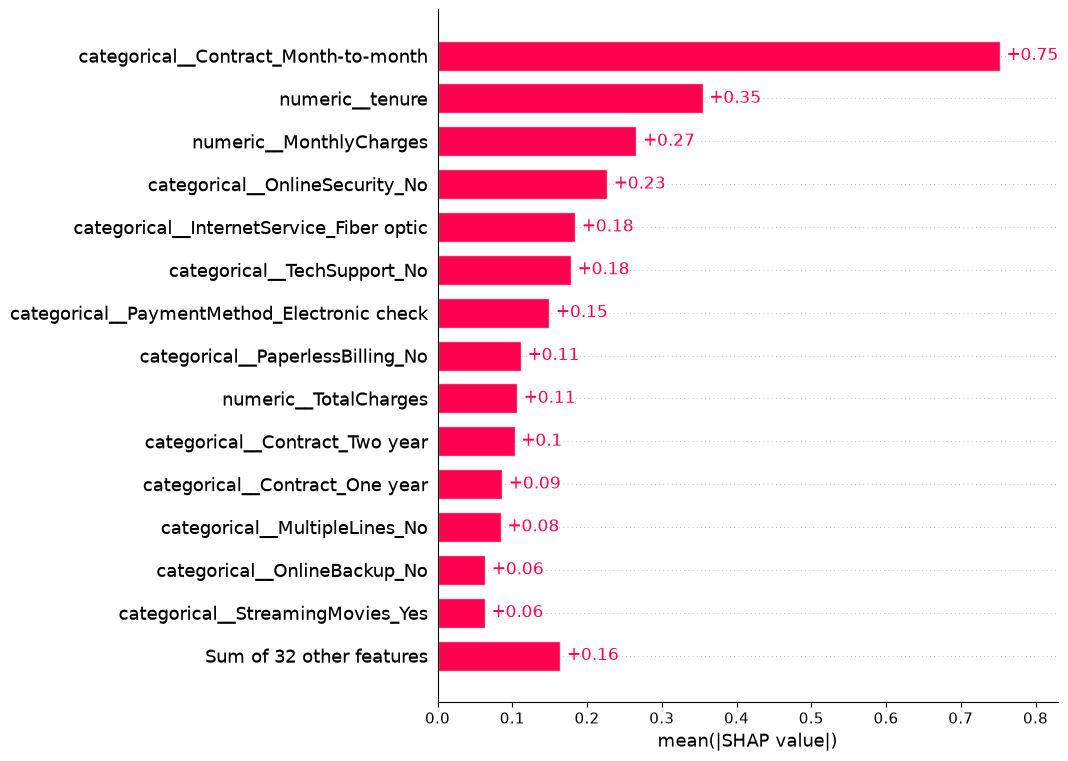

In [74]:
shap.plots.bar(
    shap_values,
    max_display=15
)

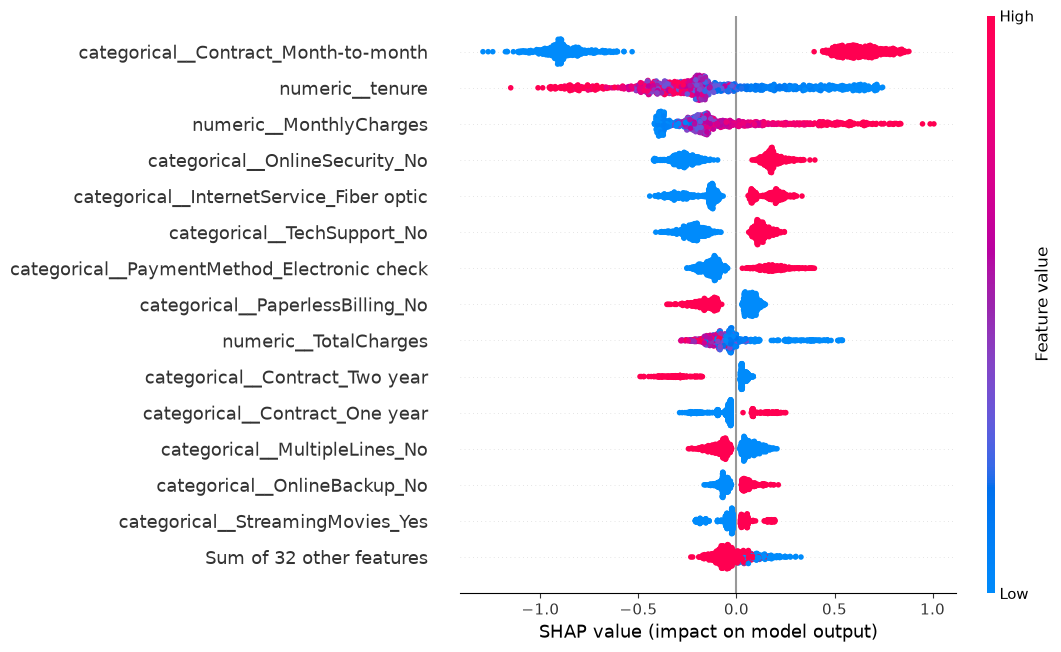

In [75]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

X ekseninde sağ: Churn yönüne etki
X ekseninde sol: No-churn yönüne etki
Kırmızı: Özellik değeri yüksek veya one-hot değeri 1
Mavi: Özellik değeri düşük veya one-hot değeri 0

In [76]:
global_importance = pd.DataFrame({
    "Özellik": feature_names,
    "Ortalama Mutlak SHAP": (
        np.abs(shap_values.values)
        .mean(axis=0)
    )
})

In [77]:
global_importance = (
    global_importance
    .sort_values(
        "Ortalama Mutlak SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

In [78]:
top_five_features = (
    global_importance.head(5)
)

top_five_features

,Özellik,Ortalama Mutlak SHAP
0,categorical__Contract_Month-to-month,0.752281
1,numeric__tenure,0.354722
2,numeric__MonthlyCharges,0.266079
3,categorical__OnlineSecurity_No,0.226930
4,categorical__InternetService_Fiber optic,0.184177


In [ ]:
Global SHAP sonuçlarına göre modelin churn tahminlerinde en etkili özellik aylık sözleşme türüdür. 
Bunu müşterinin abonelik süresi, aylık ücret, çevrim içi güvenlik hizmetine sahip olmaması ve fiber optik internet kullanımı takip etmektedir.
 Bu sonuçlar, özellikle aylık sözleşmeli, şirkete yeni katılmış ve yüksek aylık ücret ödeyen müşterilerin şirket tarafından daha yakından takip 
 edilmesinin yararlı olabileceğini göstermektedir

In [79]:
global_importance.to_csv(
    "../reports/shap_global_importance.csv",
    index=False
)

In [80]:
highest_risk_position = int(
    np.argmax(test_probabilities)
)

In [81]:
local_customer = (
    X_test.iloc[
        [highest_risk_position]
    ]
)

local_customer

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.1,95.1


In [82]:
local_probability = (
    test_probabilities[
        highest_risk_position
    ]
)

print(
    "Churn olasılığı:",
    round(local_probability, 4)
)

print(
    "Optimal eşik:",
    selected_threshold
)

Churn olasılığı: 0.9098
Optimal eşik: 0.07


In [91]:
local_transformed = (
    fitted_preprocessor.transform(
        local_customer
    )
)

if sparse.issparse(local_transformed):
    local_transformed = (
        local_transformed.toarray()
    )

In [92]:
local_shap_values = explainer(
    local_transformed
)

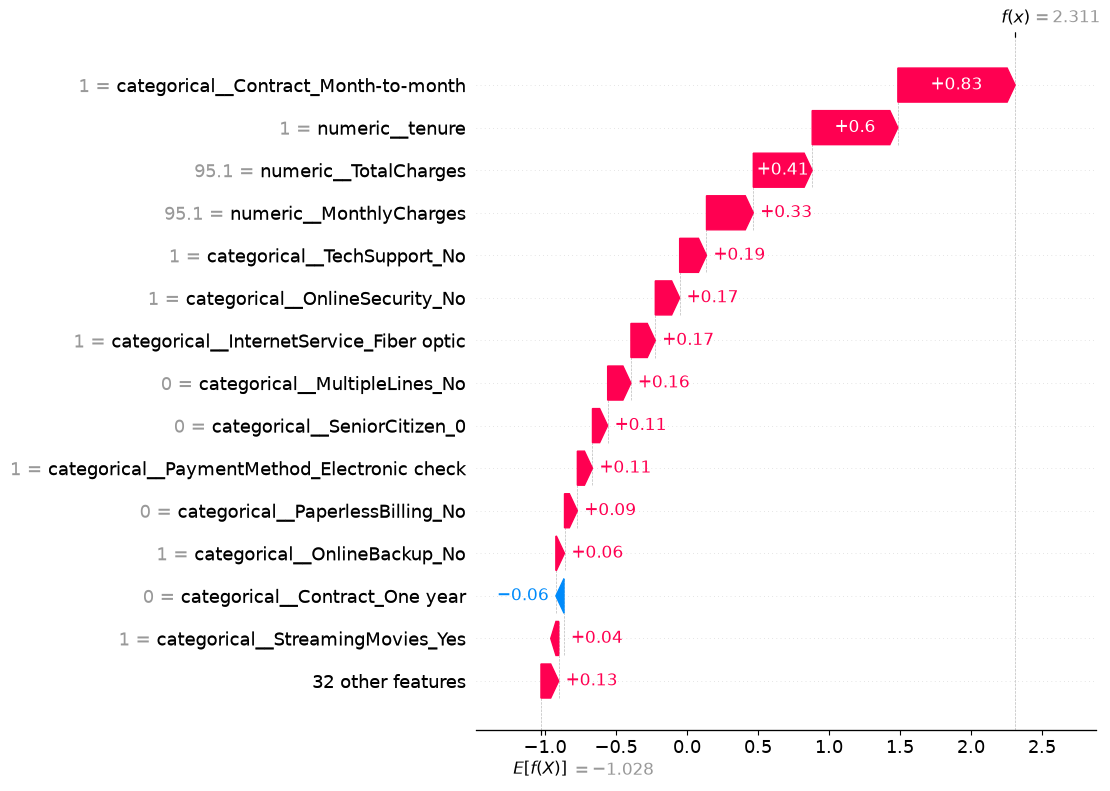

In [93]:
shap.plots.waterfall(
    local_shap_values[0],
    max_display=15
)

In [94]:
joblib.dump(
    final_pipeline,
    "../models/final_churn_pipeline.joblib"
)

['../models/final_churn_pipeline.joblib']

In [95]:
threshold_config = {
    "model_name": selected_model_name,
    "decision_threshold": selected_threshold,
    "campaign_cost": 50,
    "lost_customer_cost": 500
}

In [96]:
with open(
    "../models/threshold_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        threshold_config,
        file,
        ensure_ascii=False,
        indent=4
    )